<a href="https://colab.research.google.com/github/DevalGarg129/LunarLender/blob/main/LunarLander.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install necessary Box2D dependencies for LunarLander
!pip install swig -q
!pip install "gymnasium[box2d]" -q

In [ ]:
import gymnasium as gym

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.distributions import Categorical
from collections import deque

import random
import os

from moviepy.video.io.ImageSequenceClip import ImageSequenceClip
from IPython.display import Video, display

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)

/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


Device: cpu
PyTorch: 2.14.1+cpu


In [ ]:
env = gym.make(
    "LunarLander-v3",
    render_mode=None
)

state, info = env.reset(seed=42)

print("Observation:", state)
print("Observation shape:", state.shape)

print("Action space:", env.action_space)
print("Observation space:", env.observation_space)

Observation: [ 0.00229702  1.4181306   0.2326471   0.3204666  -0.00265488 -0.05269805
  0.          0.        ]
Observation shape: (8,)
Action space: Discrete(4)
Observation space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)


In [ ]:
class LunarLanderNN(nn.Module):
    def __init__(self, input_size=8, hidden_size=64, output_size=4):
        super(LunarLanderNN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, output_size)
        )
    def forward(self, state):
      return self.network(state)

model = LunarLanderNN().to(device)
print(model)

LunarLanderNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)


In [ ]:
# Calculate Discounted Returns
def calculate_returns(rewards, gamma=0.99):
    returns = []
    G = 0
    for reward in reversed(rewards):
        G = reward + gamma * G
        returns.insert(0, G)

    returns = torch.tensor(
        returns,
        dtype=torch.float32,
        device=device
    )

    returns = (
        returns - returns.mean()
    ) / (returns.std(unbiased=False) + 1e-8)

    return returns

In [ ]:
def train_episode(env, model, optimizer, gamma=0.99):
    state, info = env.reset()

    log_probs = []
    rewards = []

    total_reward = 0
    done = False

    while not done:
      state_tensor = torch.tensor(
          state,
          dtype=torch.float32,
      ).to(device)

      logits = model(state_tensor)
      distribution = Categorical(logits=logits)
      action = distribution.sample()
      log_prob = distribution.log_prob(action)

      next_state, reward, terminated, truncated, info = env.step(action.item())

      log_probs.append(log_prob)
      rewards.append(reward)

      total_reward += reward
      state = next_state

      done = terminated or truncated
    returns = calculate_returns(rewards, gamma)

    log_probs = torch.stack(log_probs)

    loss = -(log_probs * returns).mean()

    #back
    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    #optimizer network parameters
    optimizer.step()

    return total_reward, loss.item()

In [ ]:
EPISODES = 2000
GAMMA = 0.99
best_reward = float("-inf")
reward_history = []
recent_rewards = deque(maxlen=100)

In [ ]:
# Initialize the optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

for episode in range(EPISODES):
    episode_reward, loss = train_episode(
        env,
        model,
        optimizer,
        GAMMA
    )

    reward_history.append(episode_reward)
    recent_rewards.append(episode_reward)
    avg_reward = np.mean(recent_rewards)

    if avg_reward > best_reward:
        best_reward = avg_reward
        torch.save(
            model.state_dict(),
            "best_lunar_lander.pth"
        )
    if (episode + 1) % 50 == 0:
        print(
            f"Episode: {episode + 1}/{EPISODES} | "
            f"Reward: {episode_reward:.2f} | "
            f"Average Reward: {avg_reward:.2f} | "
            f"Loss: {loss:.4f}"
        )

Episode: 50/2000 | Reward: -384.51 | Average Reward: -177.69 | Loss: 0.0082
Episode: 100/2000 | Reward: -145.51 | Average Reward: -158.26 | Loss: -0.0029
Episode: 150/2000 | Reward: -218.05 | Average Reward: -144.59 | Loss: 0.0120
Episode: 200/2000 | Reward: -219.71 | Average Reward: -159.43 | Loss: -0.0075
Episode: 250/2000 | Reward: -209.21 | Average Reward: -174.56 | Loss: 0.0377
Episode: 300/2000 | Reward: -120.84 | Average Reward: -166.62 | Loss: -0.0393
Episode: 350/2000 | Reward: -209.28 | Average Reward: -127.12 | Loss: -0.0157
Episode: 400/2000 | Reward: -68.70 | Average Reward: -96.83 | Loss: -0.0645
Episode: 450/2000 | Reward: -59.99 | Average Reward: -98.49 | Loss: -0.0600
Episode: 500/2000 | Reward: -19.46 | Average Reward: -91.39 | Loss: -0.0268
Episode: 550/2000 | Reward: -1.56 | Average Reward: -97.78 | Loss: -0.0023
Episode: 600/2000 | Reward: -13.50 | Average Reward: -88.59 | Loss: -0.1271
Episode: 650/2000 | Reward: -57.06 | Average Reward: -82.38 | Loss: -0.0971
Epi

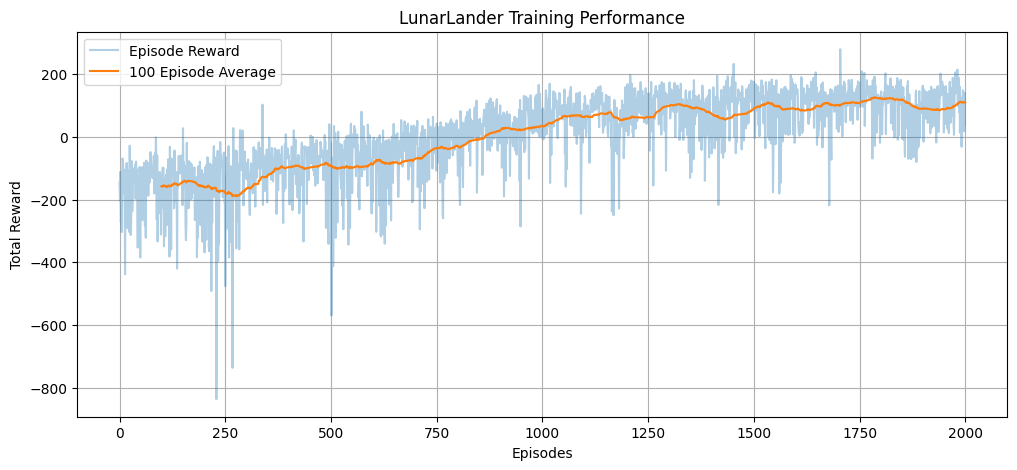

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    reward_history,
    alpha=0.35,
    label="Episode Reward"
)

# Calculate moving average
window = 100

if len(reward_history) >= window:
    moving_average = np.convolve(
        reward_history,
        np.ones(window) / window,
        mode="valid"
    )

    plt.plot(
        range(window - 1, len(reward_history)),
        moving_average,
        label="100 Episode Average"
    )

plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.title("LunarLander Training Performance")
plt.legend()
plt.grid()
plt.show()

In [ ]:
model.load_state_dict(
    torch.load(
        "best_lunar_lander.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

LunarLanderNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)

In [ ]:
eval_env = gym.make("LunarLander-v3")

for episode in range(10):
    state, info = eval_env.reset()
    total_reward = 0
    done = False

    while not done:
        state_tensor = torch.tensor(
            state,
            dtype=torch.float32
        ).to(device)

        with torch.no_grad():
            logits = model(state_tensor)
            action = torch.argmax(logits).item()

        state, reward, terminated, truncated, info = (
            eval_env.step(action)
        )

        total_reward += reward
        done = terminated or truncated
    print(
        f"Evaluation Episode {episode + 1}: "
        f"Reward = {total_reward:.2f}"
    )

eval_env.close()

Evaluation Episode 1: Reward = -9.79
Evaluation Episode 2: Reward = -41.76
Evaluation Episode 3: Reward = 10.08
Evaluation Episode 4: Reward = -4.55
Evaluation Episode 5: Reward = -47.57
Evaluation Episode 6: Reward = -19.37
Evaluation Episode 7: Reward = -55.44
Evaluation Episode 8: Reward = 9.47
Evaluation Episode 9: Reward = 25.10
Evaluation Episode 10: Reward = -21.48


In [ ]:
video_env = gym.make(
    "LunarLander-v3",
    render_mode="rgb_array"
)
state, info = video_env.reset(seed=42)

frames = []
done = False
total_reward = 0

while not done:
    # Capture current frame
    frame = video_env.render()
    frames.append(frame)
    state_tensor = torch.tensor(
        state,
        dtype=torch.float32
    ).to(device)

    # Predict action
    with torch.no_grad():
        logits = model(state_tensor)
        action = torch.argmax(logits).item()

    state, reward, terminated, truncated, info = (
        video_env.step(action)
    )

    total_reward += reward
    done = terminated or truncated
video_env.close()

print("Total Reward:", total_reward)
print("Frames captured:", len(frames))

Total Reward: -28.774516444698477
Frames captured: 1000


In [ ]:
from moviepy.video.io.ImageSequenceClip import ImageSequenceClip
clip = ImageSequenceClip(
    frames,
    fps=30
)

clip.write_videofile(
    "lunar_lander.mp4",
    codec="libx264",
    audio=False
)

Moviepy - Building video lunar_lander.mp4.
Moviepy - Writing video lunar_lander.mp4



Moviepy - Done !
Moviepy - video ready lunar_lander.mp4


In [ ]:
import base64
from IPython.display import HTML, display

def play_video(file_path):
    with open(file_path, "rb") as f:
        video_bytes = f.read()

    # Encode video to base64 string
    encoded = base64.b64encode(video_bytes).decode("ascii")

    # Generate HTML video tag
    html_code = f'''
    <video width="600" height="400" controls autoplay loop>
        <source src="data:video/mp4;base64,{encoded}" type="video/mp4">
        Your browser does not support the video tag.
    </video>
    '''
    display(HTML(html_code))

# Play the rendered Lunar Lander video
play_video("lunar_lander.mp4")

In [ ]:
!ffmpeg -y -i lunar_lander.mp4 -vcodec libx264 -f mp4 -pix_fmt yuv420p web_compatible_lunar_lander.mp4

# Play the newly converted video
play_video("web_compatible_lunar_lander.mp4")

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena